# Part B3: Synthesis (Option F: Eigenfaces)

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [11]:
faces = fetch_olivetti_faces()
X_train, X_test, y_train, y_test = train_test_split(
    faces.data.astype(np.float64), faces.target,
    test_size=0.3, stratify=faces.target, random_state=0)

mu = X_train.mean(axis=0)              # mean training face
A = (X_train - mu).T                   # 4096 x 280, columns are centred training images
U, s, Vt = np.linalg.svd(A, full_matrices=False)

# B3.1 What is the "best" k?
In B1 you found the number of components that captures 90% and 95% of the variance. In B2 you found the $k$ that gives the best classification accuracy. Do these agree? Explain why the best number of components depends on what the components are used for.

In [12]:
# Variance criterion (B1.2)
cum = np.cumsum(s**2) / np.sum(s**2)
k90 = int(np.searchsorted(cum, 0.90) + 1)
k95 = int(np.searchsorted(cum, 0.95) + 1)

# Classification criterion (B2.3): 1-NN on the scores of components start+1, ..., k
def nn_accuracy(k, start=0):
    Z_train = (X_train - mu) @ U[:, start:k]
    Z_test = (X_test - mu) @ U[:, start:k]
    knn = KNeighborsClassifier(n_neighbors=1).fit(Z_train, y_train)
    return knn.score(Z_test, y_test)

ks = np.arange(1, 111)                 # go a little past 100 so k95 is on the plot
accs = np.array([nn_accuracy(k) for k in ks])
k_best = int(ks[np.argmax(accs)])      # smallest k that reaches the best accuracy
acc_raw = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train).score(X_test, y_test)

print(f"90% of variance: k = {k90}")
print(f"95% of variance: k = {k95}")
print(f"best accuracy {accs.max():.3f}, first reached at k = {k_best}")
print(f"raw-pixel 1-NN accuracy: {acc_raw:.3f}\n")
print(f"{'k':>4} {'accuracy':>9} {'variance':>9}")
for k in [5, 10, 20, k_best, 50, k90, 100, k95]:
    print(f"{k:>4} {accs[k-1]:>9.3f} {cum[k-1]:>9.1%}")

90% of variance: k = 60
95% of variance: k = 105
best accuracy 0.900, first reached at k = 32
raw-pixel 1-NN accuracy: 0.900

   k  accuracy  variance
   5     0.700     54.1%
  10     0.833     65.6%
  20     0.892     76.7%
  32     0.900     83.2%
  50     0.900     88.2%
  60     0.900     90.1%
 100     0.900     94.6%
 105     0.900     95.0%


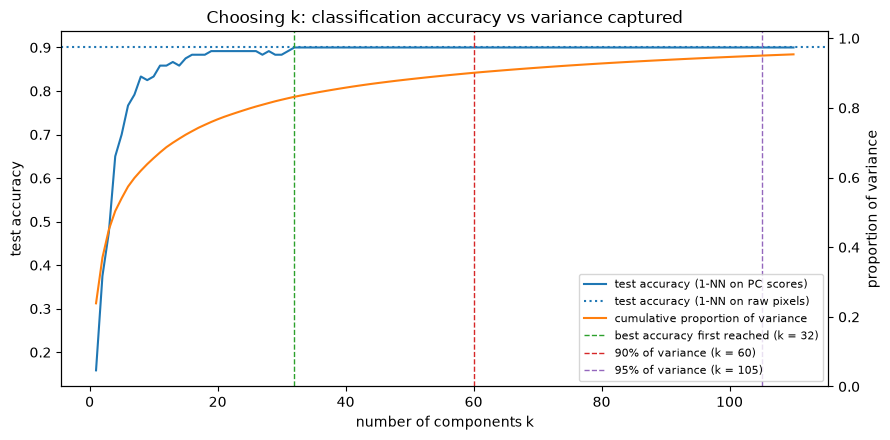

In [13]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))
l1, = ax1.plot(ks, accs, color="tab:blue", label="test accuracy (1-NN on PC scores)")
l2 = ax1.axhline(acc_raw, color="tab:blue", ls=":", label="test accuracy (1-NN on raw pixels)")
ax1.set_xlabel("number of components k")
ax1.set_ylabel("test accuracy")

ax2 = ax1.twinx()
l3, = ax2.plot(ks, cum[:len(ks)], color="tab:orange", label="cumulative proportion of variance")
ax2.set_ylabel("proportion of variance")
ax2.set_ylim(0, 1.02)

lines = [l1, l2, l3]
for kk, lab, c in [(k_best, f"best accuracy first reached (k = {k_best})", "tab:green"),
                   (k90, f"90% of variance (k = {k90})", "tab:red"),
                   (k95, f"95% of variance (k = {k95})", "tab:purple")]:
    lines.append(ax1.axvline(kk, color=c, ls="--", lw=1, label=lab))

ax1.legend(handles=lines, loc="lower right", fontsize=8)
ax1.set_title("Choosing k: classification accuracy vs variance captured")
plt.tight_layout()
plt.show()

In [14]:
# With all 279 components, 1-NN in score space makes the same decisions as 1-NN on raw pixels
k_all = int(np.sum(s > 1e-10))         # 279 (B2.1)
Z_train = (X_train - mu) @ U[:, :k_all]
Z_test = (X_test - mu) @ U[:, :k_all]
pred_all = KNeighborsClassifier(n_neighbors=1).fit(Z_train, y_train).predict(Z_test)
pred_raw = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train).predict(X_test)
print("k =", k_all, "accuracy:", (pred_all == y_test).mean())
print("same predictions as raw pixels:", np.array_equal(pred_all, pred_raw))

k = 279 accuracy: 0.9
same predictions as raw pixels: True


In [15]:
# On the plateau the accuracy is constant, but are the individual decisions the same?
def nn_predict(cols):
    knn = KNeighborsClassifier(n_neighbors=1).fit((X_train - mu) @ U[:, cols], y_train)
    return knn.predict((X_test - mu) @ U[:, cols])

pred_best = nn_predict(np.arange(k_best))
n_changed, n_flipped = [], []
for k in range(k_best + 1, k95 + 1):
    pred_k = nn_predict(np.arange(k))
    n_changed.append(np.sum(pred_k != pred_best))
    n_flipped.append(np.sum((pred_k == y_test) != (pred_best == y_test)))
print(f"k = {k_best + 1}..{k95}: at most {max(n_changed)} test predictions differ from k = {k_best}")
print(f"test faces that switch between right and wrong: {max(n_flipped)}")

k = 33..105: at most 3 test predictions differ from k = 32
test faces that switch between right and wrong: 0


**They do not agree.** In B1.2 we found that 90% of the variance needs $k = 60$ components and 95% needs $k = 105$. In B2.3 our face-recognition accuracy reached its maximum of $90\%$ already at $k = 32$, where only $83\%$ of the variance is captured, and it stays flat all the way to $k = 110$. Even $k = 20$ (77% of the variance) gives us $89.2\%$. So for our classifier the variance thresholds overshoot by a factor of 2 to 3: components 33 to 105 add variance but do not change which test faces we identify correctly. The check above shows that the same 108 of 120 faces are right at every $k$ from 32 to 105. The only predictions that move are at most 3 faces we already got wrong, which switch to a different wrong person. Our test set has only 120 images, so one image is $0.83\%$. That makes the curve a plateau rather than a sharp peak, so we take the "best" $k$ to be the smallest one on the plateau, about 30 to 40.

The plateau is exactly our raw-pixel accuracy ($90\%$), and this is no coincidence. Every centred training face $y - \mu$ lies in the column space of $U$, so for a test image $x$,
$$\lVert x - y\rVert^2 = \lVert U^T(x-\mu) - U^T(y-\mu)\rVert^2 + \lVert (I - UU^T)(x-\mu)\rVert^2 .$$
The second term is the same for every training face, so with all 279 components the nearest neighbour in score space is the nearest neighbour in pixel space. We checked this above and the predictions are identical. This tells us where the accuracy curve must end up as $k$ approaches 279, though not how it gets there. In our case the first ~30 components already pin down who is closest, and the remaining ones barely change the distances, so the curve reaches the raw-pixel value early and stays there.

**Why the best $k$ depends on the use.** The variance criterion comes from Eckart–Young: $\sum_{i>k}\sigma_i^2 = \lVert A - A_k\rVert_F^2$ is the squared reconstruction error. Choosing $k$ for 90% or 95% variance asks how many components we need to *redraw* the faces accurately, and the answer counts every pixel-level detail, whether or not it helps identify anyone. That criterion never uses the labels. Classification only needs the directions in which *different people* differ more than images of the *same person* do. Those directions are mostly among the first few dozen components, and the trailing small-$\sigma$ directions are fine detail and noise that barely change the distances (B2.3). Other uses give other answers again. For visualisation we would use $k = 2$ or $3$ whatever the variance. In our face detector from B2.4 a larger $k$ makes face space bigger, so non-faces also fit better and the residuals stop separating faces from non-faces. The "best" $k$ is the one that optimises the quantity we actually care about, and variance captured is only the right quantity when the goal is reconstruction or compression.

# B3.2 Limitations
Describe one thing PCA does poorly for your task, with an example from your results. For instance, are the leading components capturing the variation you care about, or something else? What property of PCA causes this?

PC 1: 18% of its variance is within-person
PC 2: 52% of its variance is within-person
PC 3: 22% of its variance is within-person
PC 4: 22% of its variance is within-person
PC 5: 28% of its variance is within-person
PC 6: 32% of its variance is within-person


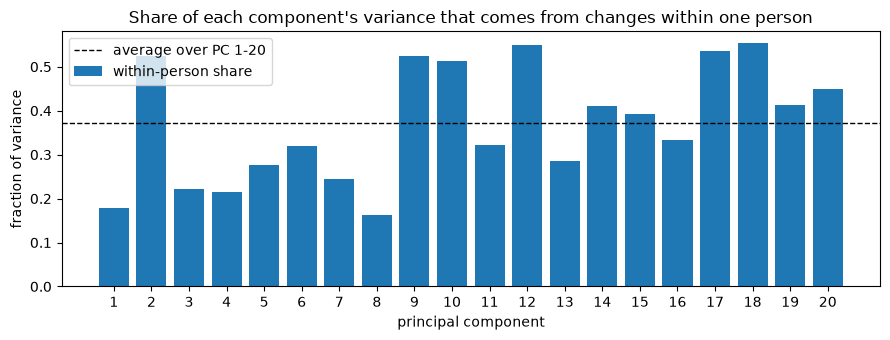

In [16]:
# How much of each component's variance is within-person (lighting, pose, expression)
# rather than between-person (identity)?
Z = (X_train - mu) @ U[:, :20]
persons = np.unique(y_train)
person_means = np.array([Z[y_train == p].mean(axis=0) for p in persons])
within = sum(((Z[y_train == p] - person_means[i])**2).sum(axis=0) for i, p in enumerate(persons))
frac_within = within / (Z**2).sum(axis=0)

for i in range(6):
    print(f"PC {i+1}: {frac_within[i]:.0%} of its variance is within-person")

plt.figure(figsize=(9, 3.5))
plt.bar(np.arange(1, 21), frac_within, color="tab:blue", label="within-person share")
plt.axhline(frac_within.mean(), color="k", ls="--", lw=1, label="average over PC 1-20")
plt.xticks(np.arange(1, 21))
plt.xlabel("principal component")
plt.ylabel("fraction of variance")
plt.title("Share of each component's variance that comes from changes within one person")
plt.legend()
plt.tight_layout()
plt.show()

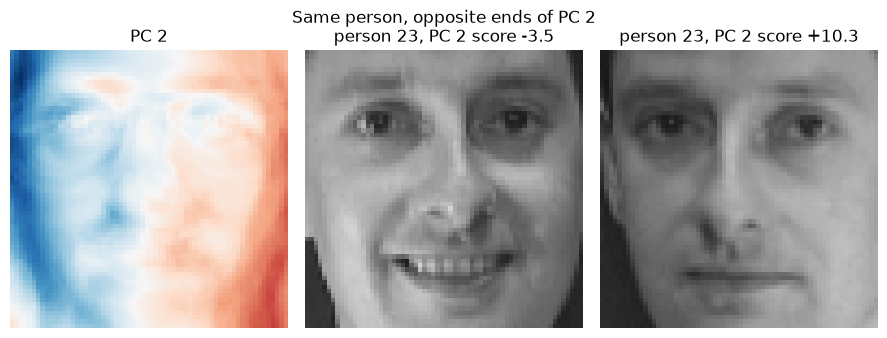

spread of person 23 along PC 2: 13.8
spread of all 40 person-means along PC 2: 11.0


In [17]:
# The person whose own images spread the most along PC 2
pc2 = Z[:, 1]
spread = [np.ptp(pc2[y_train == p]) for p in persons]
p = persons[np.argmax(spread)]
own = np.where(y_train == p)[0]
lo, hi = own[np.argmin(pc2[own])], own[np.argmax(pc2[own])]

fig, axs = plt.subplots(1, 3, figsize=(9, 3.4))
comp = U[:, 1].reshape(64, 64)
m = np.abs(comp).max()
axs[0].imshow(comp, cmap="RdBu_r", vmin=-m, vmax=m)
axs[0].set_title("PC 2")
axs[1].imshow(X_train[lo].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
axs[1].set_title(f"person {p}, PC 2 score {pc2[lo]:+.1f}")
axs[2].imshow(X_train[hi].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
axs[2].set_title(f"person {p}, PC 2 score {pc2[hi]:+.1f}")
for ax in axs:
    ax.axis("off")
fig.suptitle("Same person, opposite ends of PC 2")
plt.tight_layout()
plt.show()

print(f"spread of person {p} along PC 2: {np.ptp(pc2[own]):.1f}")
print(f"spread of all 40 person-means along PC 2: {np.ptp(person_means[:, 1]):.1f}")

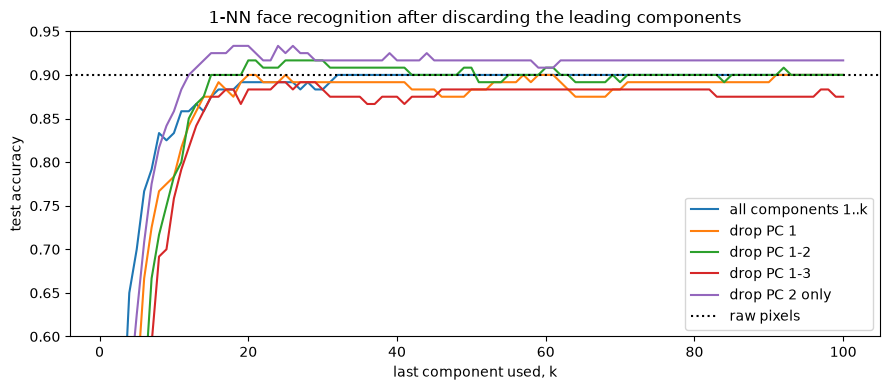

                 k = 20   k = 40   k = 60
    drop 0 PCs    0.892    0.900    0.900
    drop 1 PCs    0.900    0.892    0.900
    drop 2 PCs    0.917    0.908    0.908
    drop 3 PCs    0.883    0.875    0.883
drop PC 2 only    0.933    0.917    0.908


In [18]:
# Recognition accuracy when the leading components are thrown away
def acc_without_pc2(k):                # components 1, 3, 4, ..., k
    return np.mean(nn_predict(np.r_[0, 2:k]) == y_test)

fig, ax = plt.subplots(figsize=(9, 4))
for d in [0, 1, 2, 3]:
    kd = np.arange(d + 1, 101)
    ad = [nn_accuracy(k, start=d) for k in kd]
    lab = "all components 1..k" if d == 0 else f"drop PC 1-{d}" if d > 1 else "drop PC 1"
    ax.plot(kd, ad, label=lab)
kd = np.arange(3, 101)
ax.plot(kd, [acc_without_pc2(k) for k in kd], label="drop PC 2 only")
ax.axhline(acc_raw, color="k", ls=":", label="raw pixels")
ax.set_xlabel("last component used, k")
ax.set_ylabel("test accuracy")
ax.set_ylim(0.6, 0.95)
ax.set_title("1-NN face recognition after discarding the leading components")
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'':>14}" + "".join(f"{'k = ' + str(k):>9}" for k in [20, 40, 60]))
for d in [0, 1, 2, 3]:
    print(f"{'drop ' + str(d) + ' PCs':>14}" + "".join(f"{nn_accuracy(k, start=d):>9.3f}" for k in [20, 40, 60]))
print(f"{'drop PC 2 only':>14}" + "".join(f"{acc_without_pc2(k):>9.3f}" for k in [20, 40, 60]))

**PCA ranks directions by how much the images vary, not by whether that variation tells people apart.** For face recognition the variation we care about is identity. Much of the variation in our data is lighting, pose and expression within one person.

The clearest example we found is **PC 2**, which we identified in B1.3 as left/right illumination. Our bar chart shows that $52\%$ of its variance comes from changes *within* the same person, compared with an average of $37\%$ over PCs 1–20 and only $16$–$22\%$ for PCs 1, 3, 4 and 8. In the figure above we show person 23 at opposite ends of PC 2. The face is the same, lit from the other side. Person 23's own images spread further along PC 2 (range $13.8$) than the average faces of all 40 people do (range $11.0$). When two images of the same person differ mainly in lighting, PC 2 pushes them apart in score space, which makes nearest-neighbour errors more likely. PCs 9, 10 and 12 show the same pattern (more than half within-person).

We found that removing this "nuisance" direction helps. Keeping every other component up to $k$ and dropping only PC 2 raises our accuracy at $k = 20$ from $89.2\%$ to $93.3\%$ (5 more test faces correct), and gives $91.7\%$ at $k = 40$ and $90.8\%$ at $k = 60$, all above the raw-pixel $90\%$. This happens even though PC 2 is the second-largest-variance direction in the data, which is exactly the variance the B3.1 criterion tells us to keep. PC 1 is different: only $18\%$ of its variance is within-person, so it mostly separates people (B1.3 found it tracks overall brightness and skin tone). Dropping it alone changes the accuracy by at most one test image ($90.0\%$ at $k = 20$, $89.2\%$ at $k = 40$), and dropping PCs 1 and 2 together does no better than dropping PC 2 alone. Dropping PCs 1–3 is worse again ($88.3\%$ at $k = 20$), because PC 3 (hair and beard) is also mostly identity ($22\%$ within-person). So no fixed rule like "drop the first few" works: a good component is one that is mostly between-person, and PCA does not measure that.

**The property that causes this.** PCA is unsupervised. $u_1$ maximises $u^T S u$ over unit vectors, and $S$ is the total covariance, which splits as $S = S_{\text{between}} + S_{\text{within}}$. PCA never sees the labels, so it cannot tell whether a direction has large variance because people look different or because the lamp moved. Any strong, systematic nuisance factor, and lighting is the strongest in face photos, gets its own leading component. A second property makes this worse: PCA is linear. Lighting and pose change pixel values in a nonlinear way, so one physical change is spread over several components instead of being isolated in one. A supervised method such as LDA (Fisherfaces) would fix the first problem by maximising $u^T S_{\text{between}}\, u \,/\, u^T S_{\text{within}}\, u$ instead.